# Early Stopping

- While training NN, we have to mention that we want to run till how many epoch
- We can't run the steps for very large number of epoch as it might lead to Overfitting
- So, Early stopping helps us to stop at the point when overfitting starts


# Metrics in Early Stopping of Keras

- `monitor`: This is the metric that the callback will monitor. Common choices include 'val_loss' for validation loss or 'val_accuracy' for validation accuracy.
- `min_delta`: This is the minimum change in the monitored metric to qualify as an improvement
- `patience`: This is the number of epochs with no improvement after which training will be stopped. For example, if `patience` is set to 5, the training will stop if there is no improvement in the monitored metric for 5 consecutive epochs.
- `verbose`: This controls the verbosity of the output. If set to 1, it will print a message when training is stopped.
- `mode`: This can be 'auto', 'min', or 'max'. In 'min' mode, training will stop when the monitored metric has stopped decreasing; in 'max' mode, it will stop when the monitored metric has stopped increasing. 'auto' mode will automatically infer the mode from the name of the monitored metric.
- `baseline`: This is the baseline value for the monitored metric. Training will stop if the model doesn't show improvement over the baseline.
- `restore_best_weights`: If set to True, the model weights will be restored to the best weights obtained during training when early stopping is triggered. This can help ensure that the model retains the best performance achieved during training, even if it stops early due to lack of improvement in the monitored metric.

In [1]:
import tensorflow
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [2]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)

<Axes: >

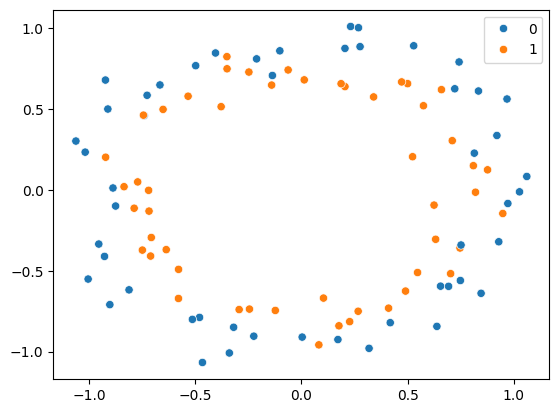

In [5]:
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [7]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [31]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=1000, verbose=0)

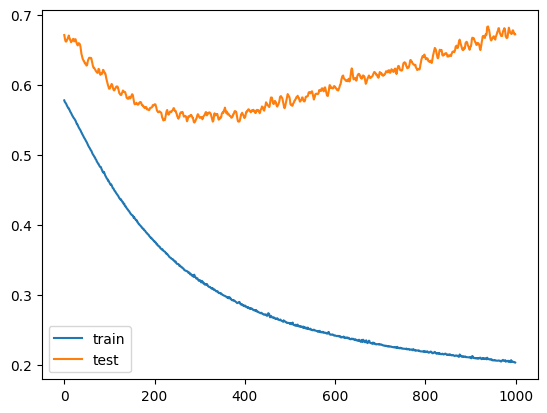

In [32]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

- So you can see in the above graph till epoch near 500, both training and validation loss are decreasing, but after that training loss is still decreasing but validation loss is increasing, which means the model is overfitting the training data and not generalizing well on the validation data.

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


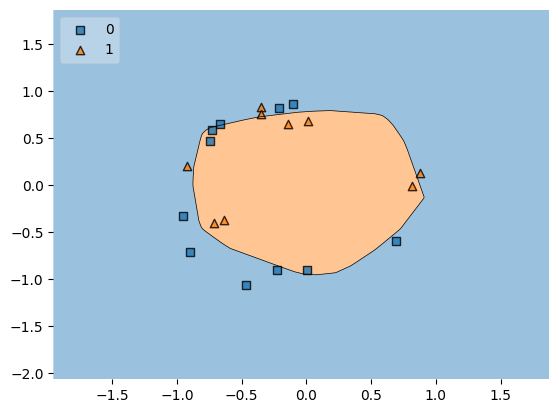

In [18]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()

# Early Stopping

In [45]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [46]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

- To implement early stopping, we can use the `EarlyStopping` callback from Keras. This callback monitors a specified metric (like validation loss) and stops training when it stops improving for a certain number of epochs (patience).

In [49]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.01,
    patience=50,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [50]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6250 - loss: 0.6547 - val_accuracy: 0.4000 - val_loss: 0.7130
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6125 - loss: 0.6541 - val_accuracy: 0.4000 - val_loss: 0.7126
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6125 - loss: 0.6531 - val_accuracy: 0.4000 - val_loss: 0.7125
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.6125 - loss: 0.6523 - val_accuracy: 0.4000 - val_loss: 0.7132
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.6250 - loss: 0.6515 - val_accuracy: 0.3500 - val_loss: 0.7124
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6250 - loss: 0.6505 - val_accuracy: 0.3500 - val_loss: 0.7122
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6250 - loss: 0.6498 - val_accuracy: 0.4000 - val_loss: 0.7117
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6250 - loss: 0.6488 - val_accuracy: 0.4000 - v

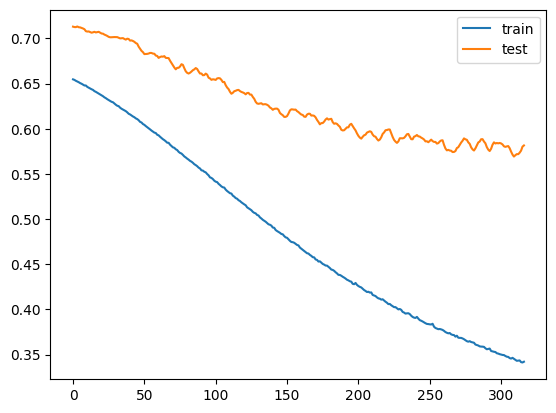

In [51]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


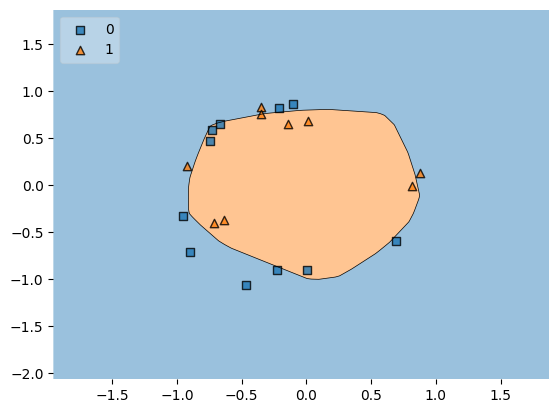

In [52]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()